<a id = "top"></a>
## **Final** (draft)

0. [Setup](#setup)
1. [Introduction](#intro)
2. [Data Cleaning](#clean)
3. [EDA](#eda)
4. [Features](#feature)
5. [Model Fitting](#fit)
6. [Final model](#model)
7. [Test](#test)
8. [Discussion](#discussion)
9. [Conclusion](#conclusion)

<a id = "setup"></a>
[<div style="text-align: right">**TOP**</div>](#top)

> ## **0. Setup**

```
0.1 Libraries
0.2 Constants (cutoffs, CV years, harbour threshold 1.5 m)
0.3 Helper functions (reshape_long, clean_error, drop_ids, add_features, make_split, get_coefs, make_fold, cv_score)
```

In [1]:
# Library

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import sklearn.pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, LinearRegression, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.kernel_ridge import KernelRidge

In [2]:
# Constants

# Used in helper functions
labels = ["avg", "min", "max"]

# Cleaning choice
tidal_threshold = 1.5  # median daily range (m) above this = tide gauge

# Time split
cutoff_val, end_val = "2025-08-31", "2025-11-30"      # validation
cutoff_final, end_final = "2026-08-31", "2026-11-30"  # final test 
cv_years = [2022, 2023, 2024, 2025]                   # one fold per autumn

# Features, target 
target = "z"
season_cols = ["sin_doy", "cos_doy"]

# model arguments
seed = 0
n_sub = 3000
alphas = np.logspace(-4, 3, 8)  # shared grid for ridge / lasso / elastic net
degrees = [1, 2, 3, 4]

In [3]:
# Helper function 1: Reshape + merge df

def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    
    """
    INPUT:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    
    OUTPUT: 
    - river long df: df with one row per station per day and columns
      (.attrs: missing_lat, missing_lon)
    """
    
    data = [avg_df, min_df, max_df]
    column = ["County", "Station_Name", "Observation_ID", "date"]
    start  = pd.Timestamp(start)
    long_df = {}

    for df, lab in zip(data, labels):

        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]  
        
        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]
    
    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left"))

    n_before = len(river_long)
    river_long = river_long.merge(loc_df, on = column[0:3], how = "left")
    assert len(river_long) == n_before, "location merged duplicated rows"

    river_long.attrs["missing_lat"] = int(river_long["Latitude"].isna().sum())
    river_long.attrs["missing_lon"] = int(river_long["Longitude"].isna().sum())
    
    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")
    
    return river_long

---

`COMMENT`

**reshape_long()**: wide files → one long table

- Raw files are *wide*: one row per station, one column per day, with separate files for avg / min / max
- Each file is **melted** to *long* format: one row per station per day
- "tidal-level" stations: measure sea level, not river level (`drop_tidal = True`)
- Days before 2017-04-01 removed: earlier years are mostly missing
- avg, min, max merged on County / Station_Name / Observation_ID / date
- Latitude / Longitude added from locations file
    - `assert` checks the merge did not duplicate rows
    - missing lat/lon counts stored in `.attrs`
- ID columns stored as `category` to save memory

**Result:** one tidy table (used by later step; cleaning, features, split)

---

In [4]:
# Helper function 2: Clean error in long_df

def clean_error(df, k = 20, cutoff = cutoff_final):
    
    """
    INPUT: 
    - df: long df that contains Observation_ID, date, avg, min, max
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    - cutoff: last day of training period
    
    OUTPUT:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    
    cutoff = pd.Timestamp(cutoff) 
    df2 = df.copy()

    err = ((df2[labels].abs() >= 9999) | (df2[labels] == -99)).any(axis = 1)   # error codes
    df2.attrs["error"] = int(err.sum())
    df2.loc[err, labels] = np.nan
                 
    for lab in labels:
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)
        
        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))

        sd = per_sta.transform("std")
        iqr = (q3 - q1).where(q3 - q1 > 0, sd)  # if iqr=0, use sd
        
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))
        
        df2.attrs[f"outliers_{lab}_all"] = int(outlier.sum())                                  
        df2.attrs[f"outliers_{lab}_test"] = int((outlier & (df2["date"] > cutoff)).sum())  
        df2.loc[outlier & (df2["date"] <= cutoff), lab] = np.nan   # blank training outliers only
    
    # blank 'impossible' days
    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan
    
    return df2

---

`COMMENT`

**clean_error()**: replace impossible or suspicious values with NaN (3 checks)

1. **Error codes** (e.g. 99999.999, -999999.999, -99)
    - sensor "no reading" placeholders, never real levels
    - flagged if |value| ≥ 9999 or = -99 in *any* of avg / min / max
    - whole day blanked: if one reading is broken, the other two are not trusted
2. **Outliers** (per station, per column)
    - fence = Q1 − k·IQR to Q3 + k·IQR, with k = 20 (very wide → only extreme spikes caught)
    - Q1, Q3, IQR computed from **training days only** (no peeking at the future)
    - if IQR = 0 (flat-lined station) → stdev used instead
    - outliers blanked in **training period only**
        - test-period outliers are only counted (i.e., real autumn flood must stay in test set)
3. **Impossible days**
    - min ≤ avg ≤ max must hold; otherwise the whole day is blanked

Counts of each step are saved in `.attrs` (error, outliers_*_all, outliers_*_test, order_violations)

**Result:** same table, with bad values as NaN (no rows removed)

---

In [5]:
# Helper function 3: drop IDs in clean_df

def drop_ids(df, min_years = 3, cutoff = cutoff_final, threshold = tidal_threshold):
    
    """
    INPUT:
    - df (long+cleaned dataframe): contains Observation_ID, date, avg, min, max
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    - cutoff: last day of training period
    - threshold: max median daily range 
    
    OUTPUT:
    - keep_df: copy of df containing only stations we keep
    """

    cutoff = pd.Timestamp(cutoff) 

    is_train = df["date"] <= cutoff
    train_obs = df["avg"].notna() & is_train
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25
    
    median_range = (df["max"] - df["min"]).where(is_train).groupby(df["Observation_ID"], observed = True).median()

    keep_ids = years[(years >= min_years) & (median_range <= threshold)].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_short"] = int((years < min_years).sum())
    keep_df.attrs["dropped_tidal"] = int((median_range > threshold).sum())
    keep_df.attrs["kept_ids"]      = int(len(keep_ids))

    return keep_df

---

`COMMENT`

**drop_ids()**: keep only stations that are (1) long enough and (2) real rivers

1. **Too short** (< 3 years of non-missing `avg` before the cutoff)
    - too little history to learn that station's mean, spread and seasonal pattern
2. **Tide gauges** (median daily range > 1.5 m)
    - harbour gauges swing several metres twice a day with the tide; rivers usually move < 0.5 m
    - clear gap in the histogram (no stations between ~1.35 and ~1.95 m) → 1.5 m cut is easy to justify
    - these measure the sea, not river flow, so they are outside the question
- Both checks use **training days only** (≤ cutoff): no information from the forecast period
- Whole stations are removed (all their rows), not individual days
- Counts saved in `.attrs`: dropped_short, dropped_tidal, kept_ids
    - a station can fail both checks, so the two dropped counts may overlap

**Result:** table with only stations we can fairly model and forecast

---

In [6]:
# Helper function 4: Split df to train/test 

def make_split(df, cutoff, end, feature_cols, target):

    """
    INPUT:
    - df: long df containing  Observation_ID, date, feature columns and target column
    - cutoff: last day of training period
    - end: last day of test period 
        - validation: cutoff = "2025-08-31", end = "2025-11-30"
        - final test: cutoff = "2026-08-31", end = "2026-11-30"
    - feature_cols: list of features names
    - target: target name to predict
    
    OUTPUT:
    - X_train, y_train, X_test, y_test
      (rows with NaN in features/target dropped; original index kept, so df.loc[X_test.index] gives matching rows)
    """
    
    cutoff, end = pd.Timestamp(cutoff), pd.Timestamp(end)
    cols = feature_cols + [target] 

    train_df = (df[df["date"] <= cutoff]
        .dropna(subset = cols)
        .sort_values(["Observation_ID", "date"]))
    
    test_df = (df[(df["date"] > cutoff) & (df["date"] <= end)]
        .dropna(subset = cols)
        .sort_values(["Observation_ID", "date"]))
    
    X_train, y_train = train_df[feature_cols], train_df[target]
    X_test, y_test = test_df[feature_cols], test_df[target]

    return X_train, y_train, X_test, y_test

---

`COMMENT`

**make_split()**: split by **time**

- **Train** = every day up to `cutoff` (31 Aug)
- **Test** = only the forecast window, `cutoff` → `end` (1 Sep – 30 Nov)
- Why not a random split?
    - random split would let the model "see" the answer from the day before/after
    - time split mimics real forecasting: only the past is known
- Used twice with different dates:
    - **validation**: train ≤ 31 Aug 2025, test Sep–Nov 2025 
    - **final test**: train ≤ 31 Aug 2026, test Sep–Nov 2026 
- Rows with missing target or feature are dropped (no imputation)
- Original row index kept → `df.loc[X_test.index]` gives station mean/std to convert predictions back to metres

**Result:** X_train, y_train, X_test, y_test ready for any sklearn model

---

In [7]:
# Helper function 5: add target (z) + features
def add_features(df, cutoff):
    
    """
    INPUT:
    - df: long df containing Observation_ID, date, avg, min, max
    - cutoff: last training date ("2025-08-31" for validation, "2026-08-31" for final test)

    OUTPUT:
    - df2: copy of df with columns added (station stats use training rows only):
        * sta_mean, sta_std: station's mean and stdev of avg level
        * z: standardized level (target)
        * daily_range: station's median (max - min), divided by its IQR of avg
        * sin_doy, cos_doy: day-of-year waves
    """
    
    df2 = df.copy()  
    cutoff = pd.Timestamp(cutoff)
    is_train = df2["date"] <= cutoff 

    train_val = df2["avg"].where(is_train)                 
    per_sta = train_val.groupby(df2["Observation_ID"], observed=True)

    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"]  = per_sta.transform("std").replace(0, np.nan)   # stdev 0 → NaN (avoid ±∞)
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]

    rng_train = (df2["max"] - df2["min"]).where(is_train)
    q1 = per_sta.transform(lambda s: s.quantile(0.25))
    q3 = per_sta.transform(lambda s: s.quantile(0.75))
    iqr = (q3 - q1).replace(0, np.nan)  # IQR 0 → NaN
    df2["daily_range"] = rng_train.groupby(df2["Observation_ID"], observed=True).transform("median") / iqr

    theta = 2 * np.pi * df2["date"].dt.dayofyear / 365.25
    df2["sin_doy"],  df2["cos_doy"]  = np.sin(theta),     np.cos(theta)      

    return df2

---

`COMMENT`

**add_features()**: build target and features (station stats from **training days only**)

1. **Target: standardised level z**
    - z = (today's level − station's mean) / station's std
    - why: every gauge has its own "zero" (one sits at ~30 m), so raw levels can't be compared across stations; z puts all stations on one scale (0 = normal, +2 = unusually high)
    - mean/std from training days only → no information from forecast period
    - std = 0 (flat-lined station) → NaN, to avoid dividing by zero
    - predictions are turned back into metres with: level = sta_mean + sta_std · $\hat z$
2. **Season: sin/cos of day of year**
    - $\theta = \frac{2 \pi · day-of-year}{365.25}$
    - day 365 and day 1 are neighbours on the calendar; sin/cos put them next to each other on a circle 
    - sin2/cos2 (two waves per year) added to test more flexible curve → no improvement, so not used
3. **Station type: daily_range**
    - median (max − min) ÷ IQR of avg: how much a station swings within a day relative to its normal spread
    - tried as a feature; lasso set it to zero → not used in the final model

**Result:** df2 with z, sta_mean, sta_std, sin/cos and daily_range added

---

In [8]:
# Helper function 6 (provided in lab5)

def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    
    """   
    INPUT:
    - m: sklearn LinearRegression model object (or pipeline with LinearRegression as final step)
    - plot: boolean value, should coefficients be plotted with error bars
    - feature_names: list of feature names to use in the plot 
    - figsize: tuple defining figure size
    - figtitle: string defining figure title
    - intercept: boolean value, should intercept be included in the plot

    OUTPUT:
    - Model coefficients in df for fitted linear model
    """
    
    # Extract intercept and coefficients into a single array
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_], 
                        m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    
    # Extract name of features
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
        
    feature_names = np.concatenate((['intercept'], feature_names))
    
    # Create df
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values ("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features'); plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        
        if figtitle is not None:
            plt.title(figtitle)
        
        plt.grid(); plt.show()
    
    return  w_df

---

`COMMENT`

**get_coefs()**: show what a fitted linear model has learned
*(taken unchanged from the MLP Workshop 5 materials; not written by us)*

- Pulls the **intercept + one coefficient per feature** out of a fitted model
    - works on a plain `LinearRegression` / `Ridge` / `Lasso`, or a pipeline that ends in one
    - feature names are read from the model (incl. one-hot county names and polynomial terms)
- Returns a table sorted from largest to smallest coefficient
- `plot = True` → horizontal bar chart (grey line at 0)
- How we use it:
    - **seasonal LR**: read off $\hat z$ = intercept + a·cos + b·sin to describe when levels peak
    - **lasso**: list which coefficients are exactly 0 → shows lat/lon, county and daily_range were dropped
    - **ridge**: see coefficients shrink as α grows
- Features are standardised first (StandardScaler) → coefficient sizes can be compared with each other

---

In [9]:
# Helper function 7: make cross-validation fold 

def make_fold(df, year):

    """
    INPUT:
    - df: cleaned long df 
    - year: autumn to validate on

    OUTPUT:
    - train_df: all days up to 31 Aug of that year
    - val_df: 1 Sep – 30 Nov of that year
    (both with z + features; rows with missing z dropped)
    """
    
    cutoff  = pd.Timestamp(f"{year}-08-31")  # last training day
    end = pd.Timestamp(f"{year}-11-30")      # last validation day

    fold_df = drop_ids(df, cutoff = cutoff)
    fold_df = add_features(fold_df, cutoff = cutoff)

    is_train = fold_df["date"] <= cutoff
    is_val = (fold_df["date"] > cutoff) & (fold_df["date"] <= end)

    train_df = fold_df[is_train].dropna(subset = ["z"])
    val_df   = fold_df[is_val].dropna(subset = ["z"])
    
    return train_df, val_df

---

`COMMENT`

**make_fold()**: build one cross-validation fold = "pretend it's 31 August of that year"

- Training = every day up to 31 Aug of `year`; validation = 1 Sep – 30 Nov of the same year
- Repeated for each year in cv_years (2022–2025) → 4 folds, each a mini version of the real task
- Training window **grows** each fold; validation is always *after* training (never trains on the future)
- Station filter (drop_ids) and features (add_features) are **recomputed inside each fold**
    - station mean/std and tide-gauge check use only that fold's training days → no information leaks from the autumn being predicted
- Why not normal k-fold? Shuffling days would put tomorrow in training and today in validation → falsely good scores
- Rows with missing z dropped (same rule as the main split)

<br>

        | fold | train | validate |
        |------|-------|----------|
        | 2022 | 2017 → Aug 2022 | Sep–Nov 2022 |
        | 2023 | 2017 → Aug 2023 | Sep–Nov 2023 |
        | 2024 | 2017 → Aug 2024 | Sep–Nov 2024 |
        | 2025 | 2017 → Aug 2025 | Sep–Nov 2025 |


**Result:** train_df, val_df for one autumn, used by cv_score()

---

In [10]:
# Helper function 8: cross-validation score 

def cv_score(model, df, features, years = cv_years, target = "z", n_sub = None):

    """
    INPUT:
    - model: unfitted sklearn model (or pipeline)
    - df: cleaned long df
    - features: list of feature column names
    - years: autumns to validate on (one fold each)
    - target: column to predict
    - n_sub: if set, fit on a random sample of this many training rows (for slow models, e.g. kernel ridge)

    OUTPUT:
    - scores: array of validation RMSE, one per fold (same order as years)
    """
    
    scores = np.zeros(len(years))
    
    for i, year in enumerate(years):
        train_df, val_df = make_fold(df, year)

        # drop rows with missing feature 
        train_df = train_df.dropna(subset = features)
        val_df = val_df.dropna(subset = features)

        if n_sub is not None:
            train_df = train_df.sample(n = n_sub, random_state = seed)

        model.fit(train_df[features], train_df[target])
        pred = model.predict(val_df[features])
        rmse = root_mean_squared_error(val_df[target], pred)

        scores[i] = rmse
        
    return scores

---

`COMMENT`

**cv_score()**: how well does a model do across several past autumns?

- For each year in cv_years (2022–2025):
    1. make_fold() → train on everything up to 31 Aug, validate on Sep–Nov of that year
    2. drop rows with missing feature 
    3. fit model on training rows
    4. predict autumn → RMSE (in z units)
- Returns **4 RMSEs**, one per autumn:
    - **mean** → typical error (used to compare models / choose α, degree)
    - **std** → how much it changes from year to year (a wet vs dry autumn)
- Why 4 autumns instead of 1?
    - single autumn can be unusually wet or dry → one score could be luck
    - averaging over several years gives a fairer comparison
- `n_sub`: fit on random sample of rows (e.g. 3000) for slow models like kernel ridge
    - `random_state = seed` → same sample every run (reproducible)
- Note: after the loop, the model is fitted on the last fold only → refit on all training data before the final test

**Result:** array of 4 RMSEs; same folds for every model → fair comparison

---

In [11]:
# Helper function 9: score prediction in z and in metres

def score(name, pred_z, y_true, df):

    """
    INPUT:
    - name: model name (for the results table)
    - pred_z: predicted z
    - y_true: true z
    - df: matching rows (needs sta_mean, sta_std, avg), e.g. final_df.loc[X_test.index]

    OUTPUT:
    - dict with RMSE (z), RMSE (m), MAE (m)
    """

    pred_m = pred_z * df["sta_std"] + df["sta_mean"]    # back to metres

    return {"model":    name,
            "RMSE (z)": root_mean_squared_error(y_true, pred_z),
            "RMSE (m)": root_mean_squared_error(df["avg"], pred_m),
            "MAE (m)":  mean_absolute_error(df["avg"], pred_m)}

<a id = "intro"></a>
[<div style = "text-align: right">**TOP**</div>](#top)

> ## **1. Introduction**

```
The question (Sep–Nov 2026 daily level), why it matters for the govt reader, and how the section is laid out
```

<a id = "clean"></a>
[<div style = "text-align: right">**TOP**</div>](#top)

> ## **2. Data Cleaning**

```
2.1 Load data reshape to long
2.2 Reshape (wide → long), clean (error codes, outliers), filter data (station, tide-levels, harbors) 
2.3 Station map/histogram
```

In [12]:
# Load data

river_avg = pd.read_csv("data/avg_river_levels.csv")
river_min = pd.read_csv("data/min_river_levels.csv")
river_max = pd.read_csv("data/max_river_levels.csv")

river_location = pd.read_csv("data/monitoring_locations.csv")

In [13]:
# Reshape, clean, filter data

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_clean = clean_error(river_long)
river_df = drop_ids(river_clean)

river_df.attrs

{'missing_lat': 0,
 'missing_lon': 0,
 'error': 78,
 'outliers_avg_all': 112,
 'outliers_avg_test': 1,
 'outliers_min_all': 179,
 'outliers_min_test': 5,
 'outliers_max_all': 145,
 'outliers_max_test': 0,
 'order_violations': 0,
 'dropped_short': 8,
 'dropped_tidal': 11,
 'kept_ids': 361}

In [14]:
# Inspect train_df 

train_df = river_df[river_df["date"] <= cutoff_final].copy()

print("Stations:", train_df["Observation_ID"].nunique())  # number of obs_id 
print("Counties:", train_df["County"].nunique())          # number of counties 
print(f"Missing avg station-days: {train_df["avg"].isna().mean() * 100:.2f} %")
print("Dates:", train_df["date"].min().date(),            # first day 
      "to", train_df["date"].max().date())                # last date

Stations: 361
Counties: 35
Missing avg station-days: 12.01 %
Dates: 2017-04-01 to 2026-08-31


---

`COMMENT:` After cleaning, 361 stations in 35 counties, Apr 2017 – Aug 2026, 12 % of days missing.

---

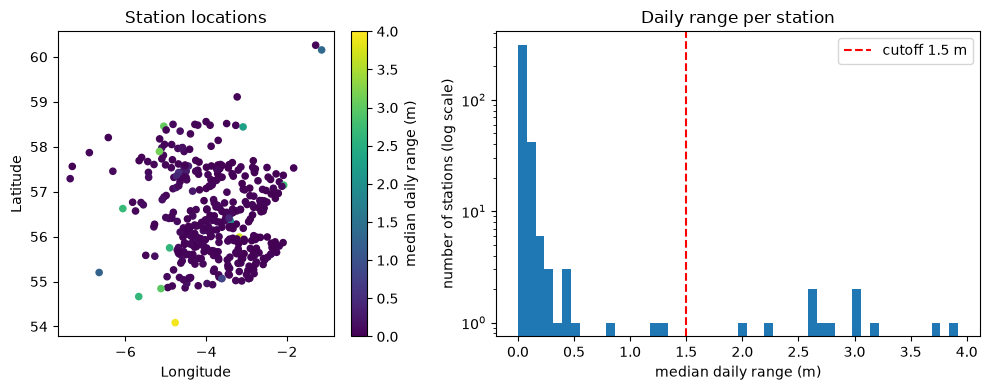

In [15]:
# Station map, histogram before filtering 

# one row per station: location + mean level (training data only)
sta_loc_avg = river_clean.groupby("Observation_ID", observed = True).agg(lat = ("Latitude", "first"), 
                                                                         lon = ("Longitude", "first"),
                                                                         level = ("avg", "mean"))

# median daily range per station 
median_range = (river_clean["max"] - river_clean["min"]).groupby(river_clean["Observation_ID"], observed = True).median()


fig, axes = plt.subplots(1, 2, figsize = (10, 4), gridspec_kw = {"width_ratios": [1, 1.4]})   # map narrower, histogram wider

# (left) station map colored by mean level
sta_map = axes[0].scatter(sta_loc_avg["lon"], sta_loc_avg["lat"], c = median_range.loc[sta_loc_avg.index], cmap = "viridis", s = 20, vmin = 0, vmax = 4)
fig.colorbar(sta_map, ax = axes[0], label = "median daily range (m)")     
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].set_title("Station locations")

# (right) histogram of median daily range
median_range.plot.hist(bins = 50, log = True, ax = axes[1])            
axes[1].axvline(1.5, color = "red", linestyle = "--", label = "cutoff 1.5 m")
axes[1].set_xlabel("median daily range (m)"); axes[1].set_ylabel("number of stations (log scale)"); axes[1].set_title("Daily range per station")
axes[1].legend()

plt.tight_layout()
plt.show()

---

`COMMENT:`

- Check if all stations record pure river-level by plotting lon/lat scatter colored by mean level<br>
  RESULT: one station was exceptionally high (~30m)
- Median daily range per stsation<br>
  <u>NOTE.</u> Tide gauge swings several meters twice a day; river usually moves few centimeters (except in floods)<br>
  RESULT: Portpatrick, Kinlochbervie, Ullapool, Leith, Port Erin (~3-4m, all are harbours)
- Plot histogram of daily range; see if sea gauges form a separate group >> choose cut-off<br>
  RESULT: big pile <0.5m (river) → few in-between stations 0.8-1.3m → empty gap 1.35-1.95m → small cluster at 2-4m (tide gauge?)

---

<a id = "eda"></a>
[<div style = "text-align: right">**TOP**</div>](#top)

> ## **3. EDA**

```
3.1 EDA plots
3.2 Correlation table
```

In [16]:
# order train_df 
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()

# avg: grouped by station
per_sta = train_df.groupby("Observation_ID", observed=True)["avg"]  

# z-score per station: (today's level − that station's mean) / that station's std
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")


train_df["year"] = train_df["date"].dt.year      # 2017, 2018, ...
train_df["month"] = train_df["date"].dt.month    # 1–12
train_df["doy"] = train_df["date"].dt.dayofyear  # day of year, 1–366

In [17]:
# sample avg_df (with no NaNs)
sample = train_df.dropna(subset = ["avg"]).sample(5000, random_state = seed)

sample["season"] = sample["month"].map({6: "Summer", 7: "Summer", 8: "Summer",    # label Jun–Aug as 'Summer'
                                        9: "Autumn", 10: "Autumn", 11: "Autumn"}) # label Sep–Nov as 'Autumn' (forecast period)
                                                                                  # ... other months -> NaN

# daily range
sample["daily_range"] = sample["max"] - sample["min"]

# autumn
autumn = sample[sample["season"] == "Autumn"]

---

`COMMENT`

**pre-EDA**: add columns needed by the plot (training data only)

- **z** (standardized level) per station = (level − station mean) / station std
    - every gauge has its own "zero", so raw levels can't be compared; z puts all stations on one scale
- **year / month / day-of-year** pulled from the date for grouping the plots
- sample 5,000 random non-missing rows (seed fixed → same sample every run)
    - violin plots / scatter of ~1M rows are slow and unreadable; sample shows the same shape
- season label: Jun–Aug = Summer (end of training), Sep–Nov = Autumn (forecast period); other months left blank
- **autumn**: Sep–Nov rows only, to compare autumns across years

---

In [18]:
# train_df in autumn 
autumn_train = train_df[train_df["month"].isin([9, 10, 11])] 

# average autumn z per station 
sta_autumn = autumn_train.groupby("Observation_ID", observed = True).agg(lat = ("Latitude", "first"),
                                                                         lon = ("Longitude", "first"),
                                                                         autumn_z = ("z", "mean")) 

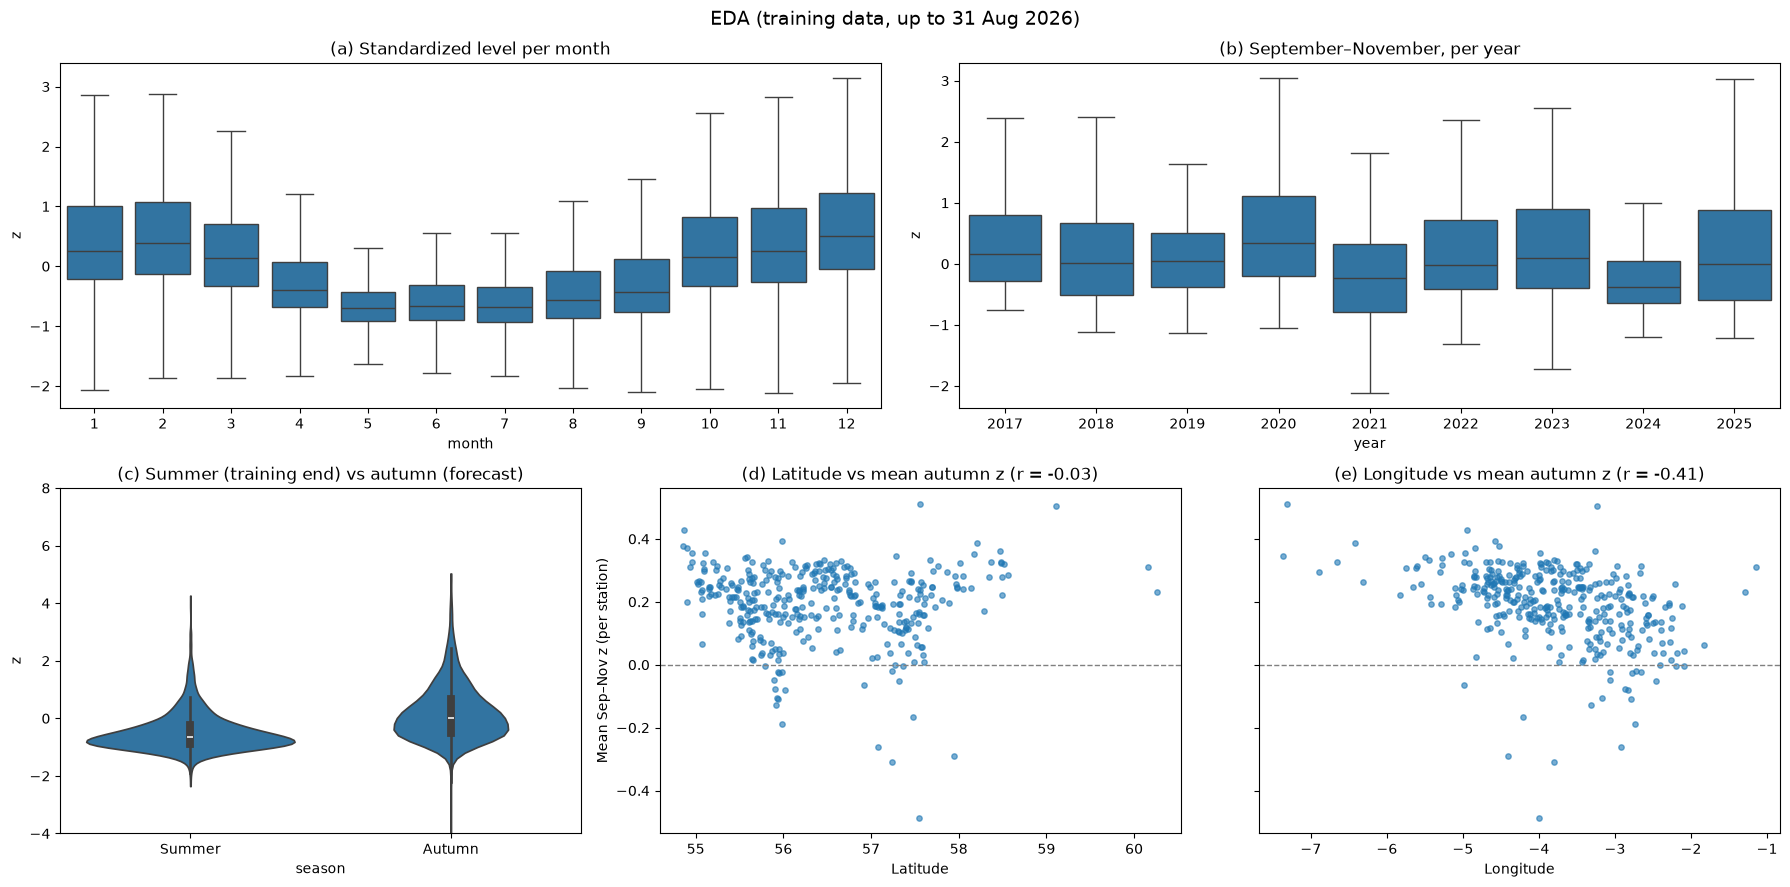

In [19]:
# EDA figure: 2 plots on top, 3 below
fig = plt.figure(figsize = (18, 9))
gs  = fig.add_gridspec(2, 6)  # 2 rows × 6 columns

ax_month  = fig.add_subplot(gs[0, 0:3])  # top-left   
ax_year   = fig.add_subplot(gs[0, 3:6])  # top-right
ax_season = fig.add_subplot(gs[1, 0:2])  # bottom-left 
ax_lat    = fig.add_subplot(gs[1, 2:4])  # bottom-middle
ax_lon    = fig.add_subplot(gs[1, 4:6], sharey = ax_lat)  # bottom-right



# (a) z per month
sns.boxplot(data = train_df, x = "month", y = "z", showfliers = False, ax = ax_month)
ax_month.set_title("(a) Standardized level per month")

# (b) autumn per year
sns.boxplot(data = autumn, x = "year", y = "z", showfliers = False, ax = ax_year)
ax_year.set_title("(b) September–November, per year")

# (c) summer vs. autumn
sns.violinplot(data = sample.dropna(subset = ["season"]), x = "season", y = "z",
               cut = 0, order = ["Summer", "Autumn"], ax = ax_season)
ax_season.set_ylim(-4, 8)
ax_season.set_title("(c) Summer (training end) vs autumn (forecast)")

# (d, e) location vs. mean autumn z, one dot per station
for ax, col, name, tag in [(ax_lat, "lat", "Latitude", "(d)"),
                           (ax_lon, "lon", "Longitude", "(e)")]:
    r = sta_autumn[col].corr(sta_autumn["autumn_z"])
    ax.scatter(sta_autumn[col], sta_autumn["autumn_z"], s = 15, alpha = 0.6)
    ax.axhline(0, color = "grey", linestyle = "--", lw = 1)
    ax.set_xlabel(name); ax.set_title(f"{tag} {name} vs mean autumn z (r = {r:.2f})")

ax_lat.set_ylabel("Mean Sep–Nov z (per station)")
ax_lon.tick_params(labelleft = False)     

fig.suptitle("EDA (training data, up to 31 Aug 2026)", fontsize = 14)
plt.tight_layout(); plt.show()

---

`COMMENT`

- **(a) z by month** (boxplot):
    - lowest in May–Jul || highest in Dec–Feb
    - jump in Oct–Nov from Sep; expect bigger forecast errors in Oct–Nov than Sep (worth checking MAE by month)
    - rises fast (Sep–Oct) + falls slowly (Feb–May); asymmetric curve ✏️ (K=2 tested → no improvement, so K=1 kept)
    - shows clear seasonal cycle >> <u>justifies</u> sin/cos season feature
- **(b) z (Sep–Nov) by year** (boxplot):
    - autumns genuinely differ from year to year
    - possible limitation; w/o additional info (weather forecast, etc.), hard to predict a wet/dry autumn
    - directly about forecast period + supports limitation point
- **(c) Summer vs. Autumn** (violin): compares end of training (Jun–Aug) with forecast months (Sep–Nov)
    - `Summer`: tight, centred around z ≈ −0.7
    - `Autumn`: centred near 0, much wider, long upper tail
    - test period behaves differently from end of training (i.e., "last known level" is NOT enough; model needs seasonal features)
    - wide autumn spread >> <u>explains</u> why autumn forecast errors are large
- **(d, e) Location vs. mean autumn z** (scatter; one dot = one station):
    - `Latitude` (r = −0.03): no pattern; north and south stations run equally high in autumn
    - `Longitude` (r = −0.41): moderate pattern; **western** stations run higher in autumn (Atlantic storms reach the west first)
    - z averages 0 for each station by construction → location can't shift the *level*; it can only change the *size* of the autumn rise (needs an interaction, e.g. cos × lon)
    - small eeffect (≈ 0 to 0.35) compared with daily variation (≈ ±1) >> expect little gain from location features; tested in model fitting

---

In [20]:
# Correlation table
train_df[["avg", "min", "max", "Latitude", "Longitude"]].corr()["avg"]

avg          1.000000
min          0.995827
max          0.994679
Latitude     0.068113
Longitude   -0.106510
Name: avg, dtype: float64

---

`COMMENT`

- **avg** almost perfectly correlated with min/max (r=0.98)
- Lat/Lon show negligible linear correlation (|r|<0.11|)<br>
  ∴ location alone cannot explain difference between rivers

---

<a id = "feature"></a>
[<div style = "text-align: right">**TOP**</div>](#top)

> ## **4. Features**

```
4.1 Target z (per-station, train-only) + why
4.2 sin/cos day-of-year (+ circle plot)
4.3 Station features tried: lat/lon, daily_range
```

In [21]:
# add sta_mean, sta_std, z (target), sin_doy/cos_doy (season features)
river_feat = add_features(river_df, cutoff = cutoff_val)

---

`COMMENT:`

- raw levels cannot be compared between stations because each gauge has its own zero, so we computed z-score per station<br>
  e.g. one gauge reads ~30 m while most read < 2 m
    - station mean/std from training days only ($\le$ cutoff), so no information from the forecast period
    - z-score per station: (today's level − that station's mean) / that station's std
    - z = 0 → normal for that station, z = +2 → unusually high
- converting back to meters; $pred_m = sta_{mean} + pred_z * sta_{std}$

---

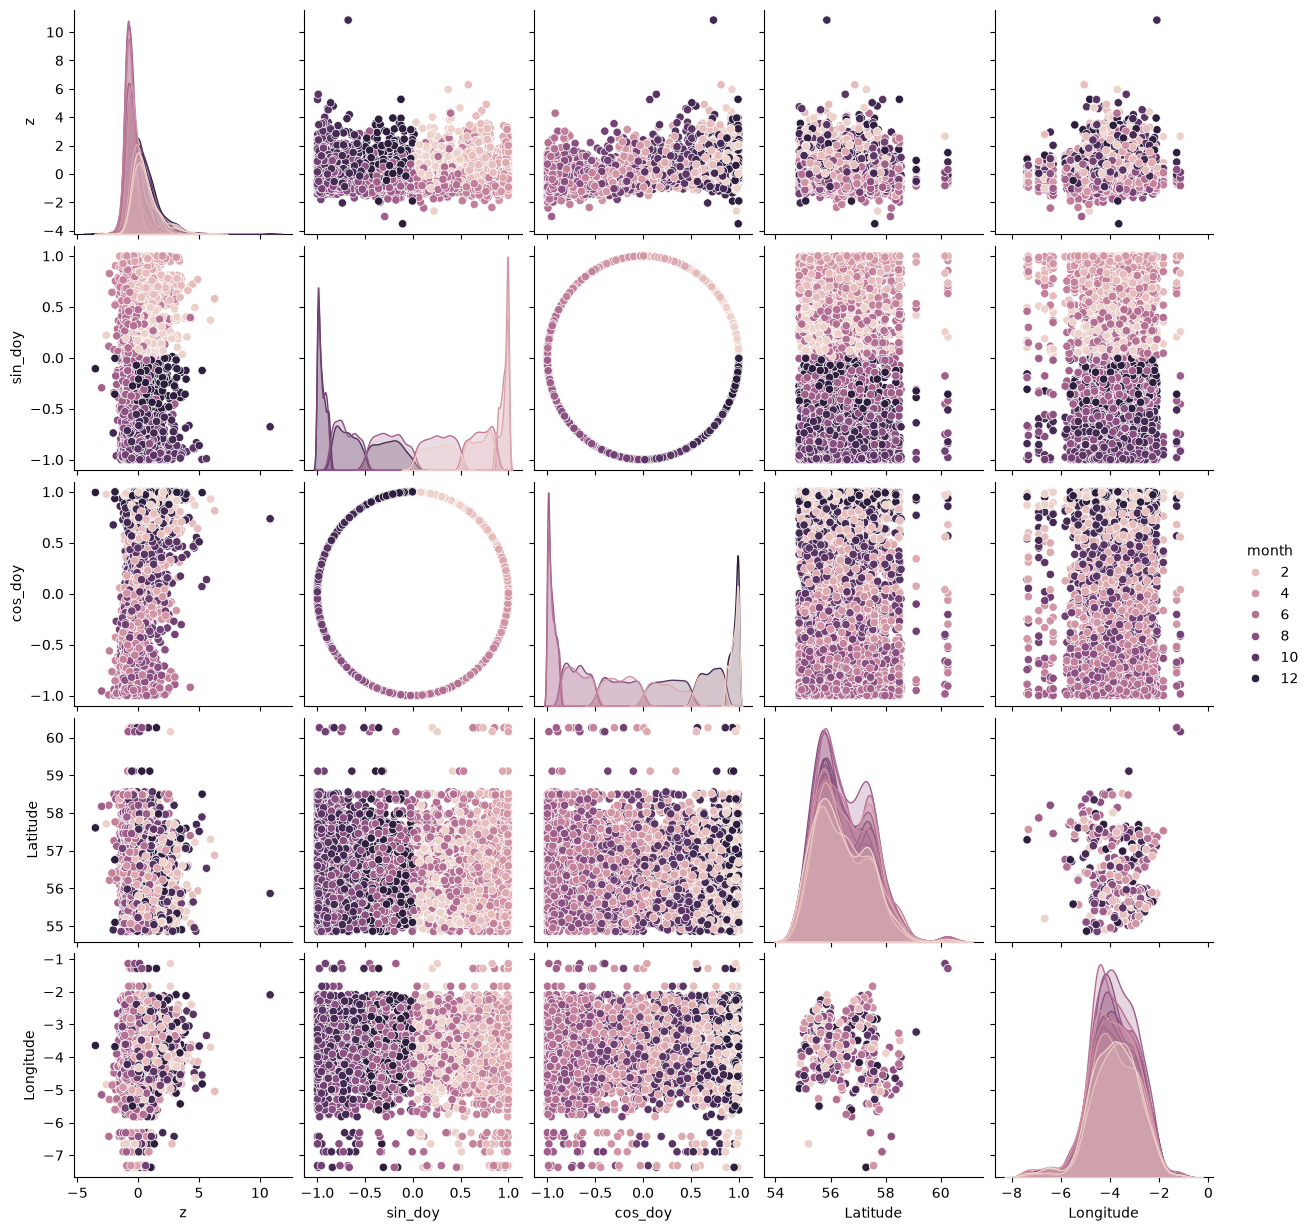

In [22]:
# pairplot 
sample = (river_feat[river_feat["date"] <= pd.Timestamp(cutoff_val)]  # training dates only
    .dropna(subset = ["z"])  
    .sample(5000, random_state = seed))

sample["month"] = sample["date"].dt.month

sns.pairplot(sample, vars = ["z", "sin_doy", "cos_doy", "Latitude", "Longitude"], hue = "month")
plt.show()

---

`COMMENT`

- `sin vs. cos`: perfect circle (months going round in order) ... _confirms encoding works_
- `Lat vs. Lon`: station map
- `z vs. lat/lon`: lat/lon (location) alone cannot explain $z$
-  `z vs. sin_doy`: vertical spread within each season (i.e., season explains only a small part of variation)
-  sin/cos place day 365 next to day 1, so the model treats late December and early January as similar

---

---

`COMMENT`

Besides the season (sin/cos), we tested whether *station-level* information helps predict z:

- **Latitude / Longitude**
    - idea: rivers in the west might rise more in autumn (wetter climate)
    - EDA panels (d, e): latitude r = -0.03 (no pattern); longitude r = -0.41 (western stations higher)
    - z already removes each station's mean and standard deviation, so location can only change the *size* of the seasonal swing, not the level
- **County** (one-hot, 34 dummies)
    - idea: coarser grouping of location 
- **daily_range** = median (max − min) ÷ IQR of avg, training days only
    - idea: separates "flashy" rivers (big swings within a day) from smooth ones
- **cos × longitude** (interaction)
    - idea from panel (e): autumn rise may be larger in the west

... Whether any of these improve forecasts is tested in Section 5 (lasso, polynomial, CV)

---

<a id = "fit"></a>
[<div style = "text-align: right">TOP</div>](#top)

> ## **5. Model Fitting**

```
5.1 Evaluation setup: time-ordered CV diagram (2022–25 folds), metrics RMSE/MAE in z and metres
5.2 Baselines: predict-0, past Sep–Nov mean, seasonal LR
5.3 Regularised linear: lasso, ridge, elastic net + α plots
5.4 Polynomial (+ degree plot)
5.5 Kernel ridge (sampled rows)
5.6 Neural network (if time)
5.7 Results table (all models, CV mean ± SD)
```

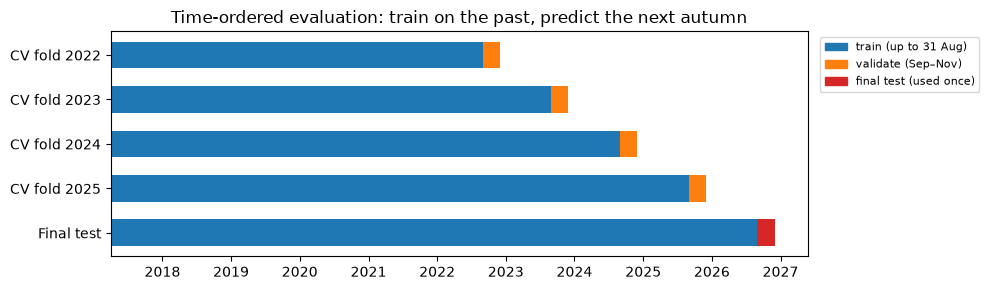

In [23]:
# CV setup diagram

from matplotlib.patches import Patch
import matplotlib.dates as mdates

start = pd.Timestamp("2017-04-01")
rows = [(f"CV fold {y}", f"{y}-08-31", f"{y}-11-30") for y in cv_years] + [("Final test", cutoff_final, end_final)]

fig, ax = plt.subplots(figsize = (10, 3))

for i, (name, cut, end) in enumerate(rows):
    cut, end = pd.Timestamp(cut), pd.Timestamp(end)
    ax.barh(i, cut - start, left = start, color = "tab:blue", height = 0.6)  # training part
    ax.barh(i, end - cut, left = cut, height = 0.6,                          # predicted autumn
            color = "tab:red" if name == "Final test" else "tab:orange")

ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(handles = [Patch(color = "tab:blue",   label = "train (up to 31 Aug)"),
                     Patch(color = "tab:orange", label = "validate (Sep–Nov)"),
                     Patch(color = "tab:red",    label = "final test (used once)")],
          loc = "upper left", bbox_to_anchor = (1.01, 1), fontsize = 8)

ax.set_title("Time-ordered evaluation: train on the past, predict the next autumn")
plt.tight_layout(); plt.show()

In [24]:
# Check: one-fold
train_check, val_check = make_fold(river_clean, 2025)

print("train:", train_check["date"].min().date(), "→", train_check["date"].max().date(),
      "|", len(train_check), "rows |", train_check["Observation_ID"].nunique(), "stations")

print("val:  ", val_check["date"].min().date(), "→", val_check["date"].max().date(),
      "|", len(val_check), "rows |", val_check["Observation_ID"].nunique(), "stations")

train: 2017-04-01 → 2025-08-31 | 950641 rows | 343 stations
val:   2025-09-01 → 2025-11-30 | 29892 rows | 331 stations


---

`COMMENT:`

- Metrics:
    - RMSE (z): main score, standardized for every station
    - MAE: typical miss
    - RMSE: punishes big misses more
    - Report CV mean ± sd. The sd shows how much the score swings between wet and dry autumns.

---

In [25]:
cv_results = []  

def add_cv(name, scores, param = None):
    cv_results.append({"model": name, 
                       "param": param,
                       "cv_mean": scores.mean(), 
                       "cv_sd": scores.std(ddof = 1)})

In [26]:
zero_scores  = np.zeros(len(cv_years))
naive_scores = np.zeros(len(cv_years))

for i, year in enumerate(cv_years):
    train_df, val_df = make_fold(river_clean, year)

    # Baseline 1: predict 0 (every station at its own normal level)
    pred_zero = np.zeros(len(val_df))
    zero_scores[i] = root_mean_squared_error(val_df["z"], pred_zero)

    # Baseline 2: each station's average autumn z from past years
    past_autumn = (train_df[train_df["date"].dt.month.isin([9,10,11])]
                   .groupby("Observation_ID", observed = True)["z"].mean())
    pred_naive = val_df["Observation_ID"].map(past_autumn).fillna(0)
    naive_scores[i] = root_mean_squared_error(val_df["z"], pred_naive)

add_cv("Predict 0 (station mean)", zero_scores)
add_cv("Past Sep–Nov mean (per station)", naive_scores)

In [27]:
season_scores = cv_score(LinearRegression(), river_clean, features = season_cols)
add_cv("Seasonal LR (sin, cos)", season_scores)

In [28]:
pd.DataFrame(cv_results).round(3)  

,model,param,cv_mean,cv_sd
0,Predict 0 (station mean),None,1.134,0.286
1,Past Sep–Nov mean (per station),None,1.127,0.209
2,"Seasonal LR (sin, cos)",None,1.084,0.180


In [29]:
pd.DataFrame({"predict 0": zero_scores,
              "past autumn": naive_scores, 
              "seasonal LR": season_scores}, index = cv_years).round(3)

,predict 0,past autumn,seasonal LR
2022,1.254,1.191,1.104
2023,1.431,1.373,1.322
2024,0.757,0.877,0.895
2025,1.094,1.066,1.015


---

`COMMENT:`

- season > predict 0; 1.134→1.084, about 4% lower error than "every river at its normal level"<br>
  VERDICT: Knowing time of year captures part of autumn rise, but most of day-to-day swing remains 
- season > past autumn history; 1.127→1.084, curve learned from all stations -> steadier than one stations's few past autumns (noisy)  
- Seasonal LR wins in 3 of 4 autumns (2022, 2023, 2025)
    - Why 2024 flips: seasonal model always predicts typical autumn rise. In 2024 the errors are low for everyone, which means rivers stayed close to normal, i.e. a quieter autumn than usual. So the model "expected rain that didn't come" and overshot, while "predict 0" happened to be right. The model bets on a typical autumn, and in an untypical one it loses.
- 2023 is the hardest year for every model (1.3–1.4). Something unusual pushed levels well above anything a calendar-based model expects. Storm Babet hit eastern Scotland in October 2023 with major flooding, which may be the cause.
- Seasonal LR had the lowest error in 3 of 4 autumns. It lost only in 2024, an unusually calm autumn, where assuming normal levels did better, showing that the model's weakness is unusual weather years.

---

```
5.3 Ridge / Lasso / Elastic net

The idea is to give the model all the candidate features, then let regularisation decide whether any of them beyond sin/cos are worth keeping.
```

In [30]:
# Define 
num_cols = ["sin_doy", "cos_doy", "Latitude", "Longitude", "daily_range"]
cat_cols = ["County"]

# Preprocessor
preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),                 
                                ("cat", OneHotEncoder(drop = "first"), cat_cols)])

In [31]:
# alpha loop with CV score 

for a in alphas:
    for name, reg in [("Ridge", Ridge(alpha = a)),
                      ("Lasso", Lasso(alpha = a)),
                      ("Elastic net", ElasticNet(alpha = a, l1_ratio = 0.5))]:
        
        model  = make_pipeline(preprocess, reg)
        scores = cv_score(model, river_clean, features = num_cols + cat_cols)    
        add_cv(name, scores, param = a)

res = pd.DataFrame(cv_results)

In [32]:
# summary table

res = res.drop_duplicates(subset = ["model", "param"])
res.loc[res.groupby("model")["cv_mean"].idxmin()]     

,model,param,cv_mean,cv_sd
14,Elastic net,0.10,1.083053,0.208828
10,Lasso,0.01,1.083049,0.185578
1,Past Sep–Nov mean (per station),NaN,1.126732,0.208969
0,Predict 0 (station mean),NaN,1.133837,0.286219
9,Ridge,0.01,1.084142,0.180380
2,"Seasonal LR (sin, cos)",NaN,1.083967,0.180352


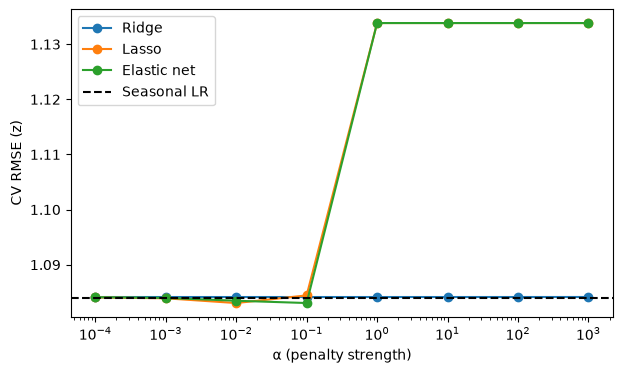

In [33]:
fig, ax = plt.subplots(figsize = (7, 4))

for name in ["Ridge", "Lasso", "Elastic net"]:
    r = res[res["model"] == name]
    ax.plot(r["param"], r["cv_mean"], marker = "o", label = name)
    
ax.axhline(season_scores.mean(), color = "k", linestyle = "--", label = "Seasonal LR")

ax.set_xscale("log"); ax.set_xlabel("α (penalty strength)"); ax.set_ylabel("CV RMSE (z)")
ax.legend(); plt.show()

---

`COMMENT`

- **Summary table** (best α per model, CV RMSE z, mean over 4 autumns):
    - Lasso (α = 0.01) 1.083
    - Elastic net (α = 0.1) 1.083
    - Seasonal LR 1.084
    - Ridge (α = 0.01) 1.084
    - differences ≈ 0.001, far smaller than year-to-year variation (sd ≈ 0.18–0.21) → no real improvement
    - all clearly beat both naive baselines (1.127, 1.134)
- **α plot**:
    - **small α (≤ 0.1)**: all three lines sit on seasonal LR line → extra features (lat/lon, daily_range, county) add nothing, even with tuning
    - **Lasso / Elastic net, α ≥ 1**: error jumps to 1.134 = "predict 0" baseline
        - penalty is so strong that *every* coefficient, including sin/cos, is set to 0 → the model predicts each station's normal level
    - **Ridge**: flat at every α
        - ridge only shrinks, never removes; with ~1M training rows, even α = 1000 is too weak to shrink much
        - best at the smallest α → no overfitting for regularisation to fix (many rows, few coefficients)
- **Conclusion**: regularised models with all features perform the same as 2-feature seasonal LR → keep **simpler seasonal LR**

---

In [34]:
# 2025-fold


train_25, val_25 = make_fold(river_clean, 2025)
train_25 = train_25.dropna(subset = num_cols + cat_cols)

# refit lasso (best a)
lasso_best = make_pipeline(preprocess, Lasso(alpha = 0.01))
lasso_best.fit(train_25[num_cols + cat_cols], train_25["z"])

# retrieve intercept + coefs per feature
w_las = get_coefs(lasso_best)

# switched off (= 0) or survived
n_zero = (w_las["coef"] == 0).sum()

print(n_zero, "of", len(w_las) -1, "coefficients are exactly 0")
w_las[w_las["coef"] != 0]

37 of 39 coefficients are exactly 0


,feature,coef
2,num__cos_doy,4.532350e-01
0,intercept,1.720122e-14
1,num__sin_doy,-2.923732e-02


---

`COMMENT:` 

- Even when given location, county and station type, lasso set all but 2 coefficients to zero, keeping only the seasonal terms.
- Lasso (α = 0.01) refitted on 2025-fold: 37 of 39 coefficients exactly 0<br>
  (39 coefficients: 5 numeric (sin, cos, lat, lon, daily_range) + 34 county dummies)
- only cos_doy (+0.45) and sin_doy (−0.03) survive → highest levels around late Dec / Jan, lowest mid-summer
    - cos = +0.45 (big): z is highest when cos is +1, i.e. around 1 January, and lowest around 1 July. That's the winter-high / summer-low cycle from EDA panel (a)
    - sin = −0.03 (tiny): shifts that peak only a few days earlier (around late December). So the curve is almost a pure winter peak
- location (lat/lon), county and daily_range all removed, even longitude (r = −0.41 in EDA panel e):
  its effect is on the *size* of the autumn rise, which an additive term cannot use
- intercept ≈ 0, as expected for a standardised target
- → confirms the seasonal LR (sin, cos) as the model to carry forward

---

In [35]:
# CV, polynomial regressoin 

poly_cols = ["sin_doy", "cos_doy", "Latitude", "Longitude"]

poly_preprocessor = make_column_transformer(("passthrough", ["sin_doy", "cos_doy"]),
                                            (StandardScaler(), ["Latitude", "Longitude"]),
                                            verbose_feature_names_out = False)

poly_scores = {}

for d in degrees:
    model = make_pipeline(poly_preprocessor,
                          PolynomialFeatures(degree = d, include_bias = False), 
                          LinearRegression())
    poly_scores[d] = cv_score(model, river_clean, features = poly_cols)
    add_cv("Polynomial (sin, cos, lat, lon)", poly_scores[d], param = d)

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])
res[res["model"].str.startswith("Polynomial")]

,model,param,cv_mean,cv_sd
27,"Polynomial (sin, cos, lat, lon)",1.0,1.083968,0.180481
28,"Polynomial (sin, cos, lat, lon)",2.0,1.086993,0.189935
29,"Polynomial (sin, cos, lat, lon)",3.0,1.079928,0.167373
30,"Polynomial (sin, cos, lat, lon)",4.0,1.080067,0.165798


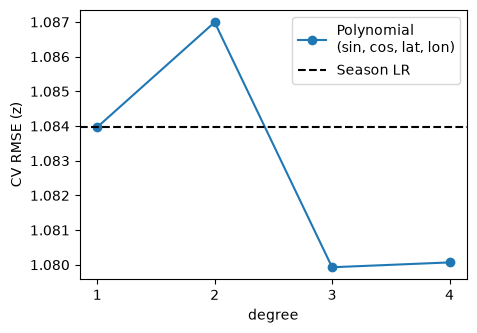

In [36]:
# plot

r = res[res["model"] == "Polynomial (sin, cos, lat, lon)"]

fig, ax = plt.subplots(figsize = (5, 3.5))

ax.plot(r["param"], r["cv_mean"], marker = "o", label = "Polynomial\n(sin, cos, lat, lon)")
ax.axhline(season_scores.mean(), color = "k", linestyle = "--", label = "Season LR")

ax.set_xticks([1,2,3,4])
ax.set_xlabel("degree")
ax.set_ylabel("CV RMSE (z)")
ax.legend()

plt.show()

In [37]:
# season score vs. poly deg-3
pd.DataFrame({"seasonal LR": season_scores,
             "poly deg-3": poly_scores[3],
             "diff": poly_scores[3] - season_scores}, index = cv_years).round(3)

,seasonal LR,poly deg-3,diff
2022,1.104,1.096,-0.008
2023,1.322,1.305,-0.017
2024,0.895,0.916,0.020
2025,1.015,1.003,-0.012


In [38]:
# interaction coefficient (check via train_25)

poly_best = make_pipeline(poly_preprocessor,
                         PolynomialFeatures(degree = 3, include_bias = False),
                         LinearRegression())

poly_best.fit(train_25[poly_cols], train_25["z"])

w_poly = get_coefs(poly_best)
w_poly.head(), w_poly.tail()

(              feature      coef
 2             cos_doy  0.505903
 16  sin_doy^2 cos_doy  0.443898
 6     sin_doy cos_doy  0.120948
 8   sin_doy Longitude  0.070780
 25          cos_doy^3  0.062005,
                        feature      coef
 23  sin_doy Latitude Longitude -0.014063
 29  cos_doy Latitude Longitude -0.016122
 22          sin_doy Latitude^2 -0.023095
 20    sin_doy cos_doy Latitude -0.083290
 21   sin_doy cos_doy Longitude -0.151427)

In [39]:
# predicted by EDA
w_poly[w_poly["feature"].isin(["cos_doy Longitude", "sin_doy, cos_doy Longitude"])]

,feature,coef
11,cos_doy Longitude,0.039409


---

`COMMENT:`

- Polynomial features on `sin`, `cos`, `lat`, `lon` (degree 1-4), plain linear regression, 4-fold CV
    - degree 1 = 1.0840; degree 2 = 1.0870; **degree 3 = 1.0799**; degree 4 = 1.0800
- degree 3 vs. seasonal LR, per autumn: better in 2022, 2023, 2025 (by ~0.01), worse in 2024 (calm autumn)
- refit on 2025-fold (34 terms); largest terms -> season-only ($\sin^{2}•cos, sin •cos$)
    - seasonal curve; slightly asymmetric (fast autumn rise, slow spring fall) ... as in EDA(a)
- small location term: $\cos × lon = 0.0394$ (positive sign supports "bigger swing in east")  
- poly-3; best scoring model but the gain is too small to justify its complexity (it does show seasonal curve is slightly asymmetric + varies a little with longitude) 

---

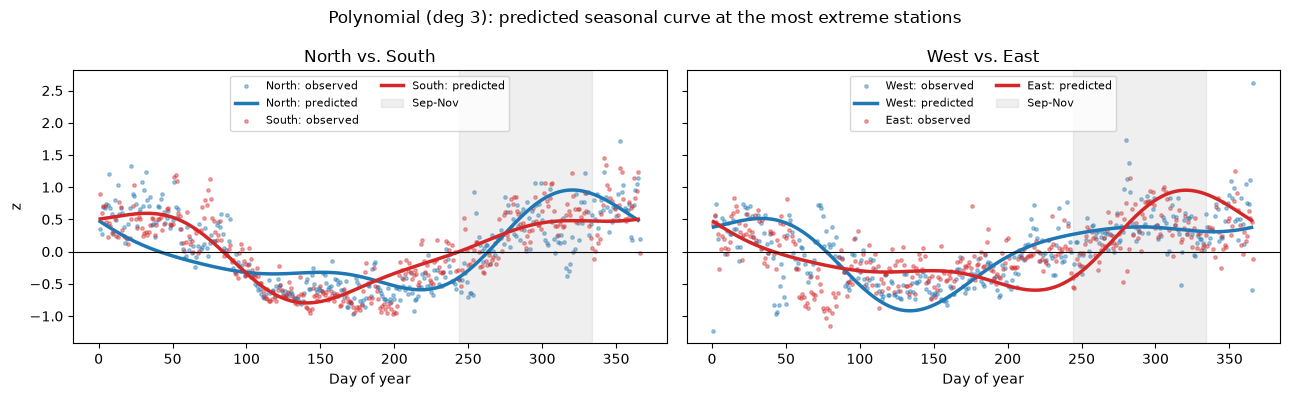

In [40]:
# plot

sta_loc = train_25.groupby("Observation_ID", observed = True)[["Latitude", "Longitude"]].first()

pairs = {"North vs. South": [(sta_loc["Latitude"].idxmax(), "tab:blue", "North"),
                             (sta_loc["Latitude"].idxmin(), "tab:red", "South")],
         "West vs. East": [(sta_loc["Longitude"].idxmin(), "tab:blue", "West"),
                           (sta_loc["Longitude"].idxmax(), "tab:red", "East")]}

doy = np.arange(1, 366)
theta = 2 * np.pi * doy / 365.25


fig, axes = plt.subplots(1, 2, figsize = (13, 4), sharey = True)

for ax, (title, stations) in zip(axes, pairs.items()):
    for sta_id, color, name in stations: 
        sta = train_25[train_25["Observation_ID"] == sta_id]
        obs = sta.groupby(sta["date"].dt.dayofyear)["z"].mean()
        grid = pd.DataFrame({"sin_doy": np.sin(theta), "cos_doy": np.cos(theta),
                            "Latitude": sta["Latitude"].iloc[0], "Longitude": sta["Longitude"].iloc[0]})

        ax.scatter(obs.index, obs.values, s = 6, alpha = 0.4, color = color, label = f"{name}: observed")
        ax.plot(doy, poly_best.predict(grid[poly_cols]), color = color, lw = 2.5, label = f"{name}: predicted")

    ax.axvspan(244, 334, color = "grey", alpha = 0.12, label = "Sep-Nov")
    ax.axhline(0, color = "k", lw = 0.8)
    
    ax.set_xlabel("Day of year")
    ax.set_title(title)
    ax.legend(fontsize = 8, loc = "upper center", ncol = 2)

axes[0].set_ylabel("z")
fig.suptitle("Polynomial (deg 3): predicted seasonal curve at the most extreme stations")
plt.tight_layout()
plt.show()

In [41]:
# percentage change of seasonal score and polynomial score
((season_scores.mean() - poly_scores[3].mean()) / poly_scores[3].mean()).round(3) * 100

np.float64(0.4)

`COMMENT:`

- curves from cv-selected polynomial (deg 3, plain LR) -> refitted on 2025-fold
    - earlier ver. (deg-2, ridge $\alpha$ = 1, chosen BEFORE tuning) -> gave smoother single wave
- deg-3 of sin/cos adds waves with 2 and 3 cycles per year (e.g., $\cos(3\theta) = 4\cos^{3}(\theta) - 3\cos(\theta)$)<br>
  (i.e., curve becomes squiggly rather than one smooth curve)
- north vs. south: curves nearly the same
- deg-3 model scores slightly better on average (0.4%) but for stations at the edge of the map it produces unrealistic seasonal curves that don't match their own data.
    - simple seasonal LR have no problem 

In [42]:
# kernel ridge regression 

krr_cols = ["sin_doy", "cos_doy", "Latitude", "Longitude"]
krr_alphas = np.logspace(-2, 2, 5)
krr_gammas = [0.01, 0.1, 1, 10]

for a in krr_alphas:
    for g in krr_gammas:
        krr = make_pipeline(poly_preprocessor, KernelRidge(kernel = "rbf", alpha = a, gamma = g))
        scores = cv_score(krr, river_clean, features = krr_cols, n_sub = 3000)
        add_cv("Kernel ridge (RBF)", scores, param = f"ɑ = {a}, γ = {g}")

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])

In [43]:
# table

res[res["model"] == "Kernel ridge (RBF)"].sort_values("cv_mean").head(5)

,model,param,cv_mean,cv_sd
39,Kernel ridge (RBF),"ɑ = 1.0, γ = 0.01",1.078880,0.189530
35,Kernel ridge (RBF),"ɑ = 0.1, γ = 0.01",1.080272,0.194883
44,Kernel ridge (RBF),"ɑ = 10.0, γ = 0.1",1.081262,0.197150
31,Kernel ridge (RBF),"ɑ = 0.01, γ = 0.01",1.081813,0.199268
40,Kernel ridge (RBF),"ɑ = 1.0, γ = 0.1",1.082057,0.193646


---

`COMMENT:`

- Kernel ridge regression (RBF kernel): flexible, non-linear model ... predicts a day's `z` from _similar_ training days<br>
  (i.e., 'similar' ... close in season and location; RBF kernel -> gives near neighbors a big weight, far ones ~0
- two settings, tuned together by CV (5 x 4 = 20 combinations):
    - γ (gamma): how quickly similarity fades with distance<br>
      (large γ -> only very close days count (wiggly fit); small γ -> smooth fit)
    - ɑ (alpha): ridge penalty (larger ɑ -> smoother, less flexible)
- trained on 3000 random rows per fold via `n_sub`
    - kernel ridge; compares every training row with every other row -> 800k rows would need far too much memory (i.e., its scores are from a much smaller training set than the other models)
- BEST: $\alpha = 1, \gamma = 0.01$ -> CV RMSE 1.079 (vs. seasonal LR 1.084, poly-3 1.080)
    - CV chose smoothest kernel ($\gamma$ = 0.01) -> flexible model also settles on smooth seasonal curve
    - even from only 3000 rows it matches the best models (~1.08)
        - seasonal pattern = simple
        - remaining error; day-to-day weather that season + location cannot explain (... not a lack of model flexibility) 

In [44]:
# results table 

res = pd.DataFrame(cv_results).drop_duplicates(subset = ["model", "param"])

# best setting of each model 
best = res.loc[res.groupby("model")["cv_mean"].idxmin()].copy()

best = best.sort_values("cv_mean").reset_index(drop = True)
best[["model", "param", "cv_mean", "cv_sd"]].round(3)

,model,param,cv_mean,cv_sd
0,Kernel ridge (RBF),"ɑ = 1.0, γ = 0.01",1.079,0.190
1,"Polynomial (sin, cos, lat, lon)",3,1.080,0.167
2,Lasso,0.01,1.083,0.186
3,Elastic net,0.1,1.083,0.209
4,"Seasonal LR (sin, cos)",None,1.084,0.180
5,Ridge,0.01,1.084,0.180
6,Past Sep–Nov mean (per station),None,1.127,0.209
7,Predict 0 (station mean),None,1.134,0.286


|	model|	param|	cv_mean|	cv_sd|	vs. seasonal LR|	note|
|---|---|---|---|---|---|
|Kernel ridge (RBF)	|ɑ = 1.0, γ = 0.01	|1.079	|0.190|	-0.005|	kernel, 3000 rows/fold|
|Polynomial (sin, cos, lat, lon)|	3	|1.080|	0.167|	-0.004	|34 terms (deg 3)|
|Lasso|	0.01	|1.083	|0.186	|-0.001	|39 → 2 coefs|
|Elastic net|	0.1	|1.083|	0.209	|-0.001|	39 coefs (penalized)|
|Seasonal LR (sin, cos)|	None|	1.084|	0.180|	-- |	2 coefs|
|Ridge	|0.01	|1.084	|0.180	|0.000	|39 coefs|
|Past Sep–Nov mean (per station) |	None	|1.127	|0.209	|0.043|	NaN|
|Predict 0 (station mean)|	None|	1.134	|0.286|	0.050	|none|


<a id = "model"></a>
[<div style = "text-align: right">TOP</div>](#top)

> ## **6. Final Model**

```
6.1 Choice + why (simplest model within noise of best)
6.2 One-time 2026 test score
6.3 Actual vs predicted for 2–3 stations, error by month
6.4 What the coefficients mean (peak in winter, amplitude)
```

In [45]:
# choice: seaosonal baseline

In [46]:
# Final model: retrain on ALL training data (up to 31 Aug 2026), test once on Sep–Nov 2026

final_df = drop_ids(river_clean, cutoff = cutoff_final)
final_df = add_features(final_df, cutoff = cutoff_final)

X_train, y_train, X_test, y_test = make_split(final_df, cutoff = cutoff_final, end = end_final,
                                              feature_cols = season_cols, 
                                              target = "z")

final_model = LinearRegression().fit(X_train, y_train)
get_coefs(final_model)                                  

,feature,coef
2,cos_doy,0.656768
0,intercept,0.033124
1,sin_doy,-0.035633


```
Fitted model: ẑ = 0.033 + 0.657·cos_doy − 0.036·sin_doy
```

In [47]:
# Test on Sep–Nov 2026
test_rows = final_df.loc[X_test.index]

test_results = pd.DataFrame([score("Predict 0 (station mean)",  # baseline 
                                   np.zeros(len(X_test)),         
                                   y_test, test_rows),   
                             score("Seasonal LR (final)",       # seasonal model
                                   final_model.predict(X_test), 
                                   y_test, test_rows)]).set_index("model").round(3)

test_results

,RMSE (z),RMSE (m),MAE (m)
model,,,
Predict 0 (station mean),0.962,0.193,0.138
Seasonal LR (final),0.955,0.190,0.135


---

`COMMENT:`

- on typical autumn day; forecast = off by about 13-14 cm (MAE)<br>
  <u>NOTE.</u> larger misses on storm days push RMSE to ~19 cm
- better performance than baseline but only by little
- autumn 2026; calmer than average (... similar to that of 2024 autumn)<br>
  <u>NOTE.</u> in calmer autumn; "normal level" is already a good guess (i.e., knowing season adds little)

On the unseen Sep–Nov 2026 data, the seasonal model's typical error was 13.5 cm (MAE), slightly better than assuming each river stays at its normal level (13.8 cm). The small gain reflects a relatively calm autumn; most of the remaining error comes from day-to-day weather, which the model does not use.

---

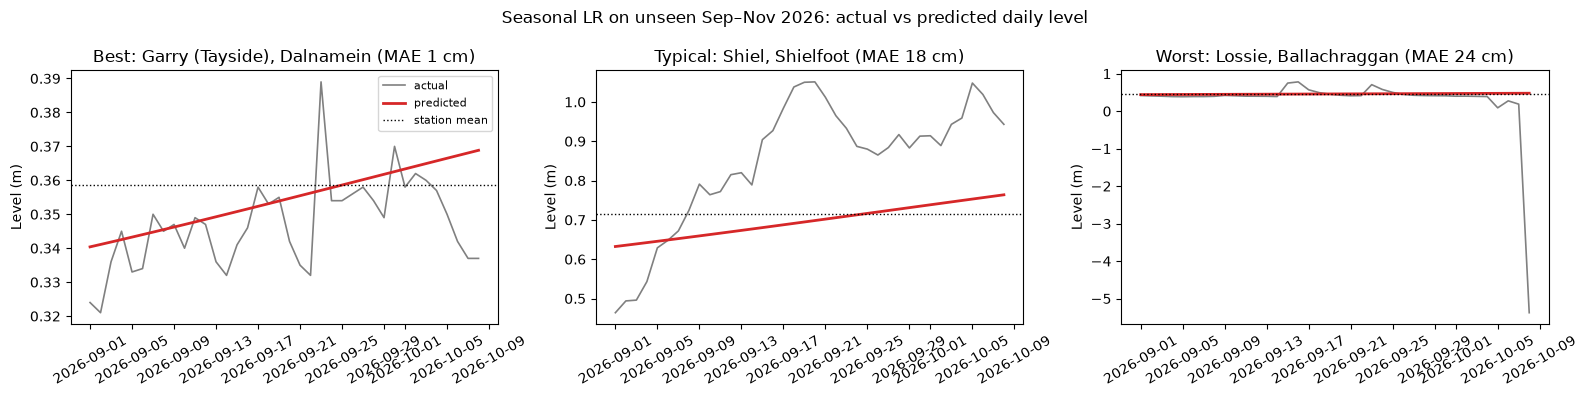

In [48]:
# 6.3 Actual vs predicted on the unseen Sep–Nov 2026 (final seasonal LR)
test_rows = final_df.loc[X_test.index].copy()

test_rows["pred_z"]  = final_model.predict(X_test)
test_rows["pred_m"]  = test_rows["pred_z"] * test_rows["sta_std"] + test_rows["sta_mean"]   # back to metres
test_rows["err_z"]   = (test_rows["z"] - test_rows["pred_z"]).abs()      # for ranking (fair across river sizes)
test_rows["abs_err"] = (test_rows["avg"] - test_rows["pred_m"]).abs()    # in metres, for the reader

# best / typical / worst station by average z-error
sta_err = test_rows.groupby("Observation_ID", observed = True)["err_z"].mean().sort_values()
picks = {"Best": sta_err.index[0], "Typical": sta_err.index[len(sta_err) // 2], "Worst": sta_err.index[-1]}

fig, axes = plt.subplots(1, 3, figsize = (16, 4))

for ax, (label, sta_id) in zip(axes, picks.items()):
    sta = test_rows[test_rows["Observation_ID"] == sta_id].sort_values("date")
    mae_cm = sta["abs_err"].mean() * 100
    ax.plot(sta["date"], sta["avg"],    color = "grey",    lw = 1.2, label = "actual")
    ax.plot(sta["date"], sta["pred_m"], color = "tab:red", lw = 2,   label = "predicted")
    ax.axhline(sta["sta_mean"].iloc[0], color = "k", ls = ":", lw = 1, label = "station mean")
    ax.set_title(f"{label}: {sta['Station_Name'].iloc[0]} (MAE {mae_cm:.0f} cm)")
    ax.set_ylabel("Level (m)")
    ax.tick_params(axis = "x", rotation = 30)

axes[0].legend(fontsize = 8)
fig.suptitle("Seasonal LR on unseen Sep–Nov 2026: actual vs predicted daily level")
plt.tight_layout(); plt.show()

In [49]:
# choice: polynomial 

In [50]:
X_train, y_train, X_test, y_test = make_split(final_df, cutoff = cutoff_final, end = end_final,
                                              feature_cols = poly_cols,
                                              target = "z")

final_model = make_pipeline(poly_preprocessor,
                            PolynomialFeatures(degree = 3, include_bias = False),
                            LinearRegression()).fit(X_train, y_train)

pred_z = final_model.predict(X_test)

# Test results next to the baselines, all on the SAME test rows
seasonal = LinearRegression().fit(X_train[season_cols], y_train)

test_df = final_df.loc[X_test.index]   # same rows as X_test (make_split keeps the index)

test_results = pd.DataFrame([
    score("Predict 0 (station mean)", np.zeros(len(y_test)), y_test, test_df),
    score("Seasonal LR", seasonal.predict(X_test[season_cols]), y_test, test_df),
    score("Poly deg 3 (final)", pred_z, y_test, test_df),
]).round(3)
test_results

,model,RMSE (z),RMSE (m),MAE (m)
0,Predict 0 (station mean),0.962,0.193,0.138
1,Seasonal LR,0.955,0.190,0.135
2,Poly deg 3 (final),0.907,0.177,0.121


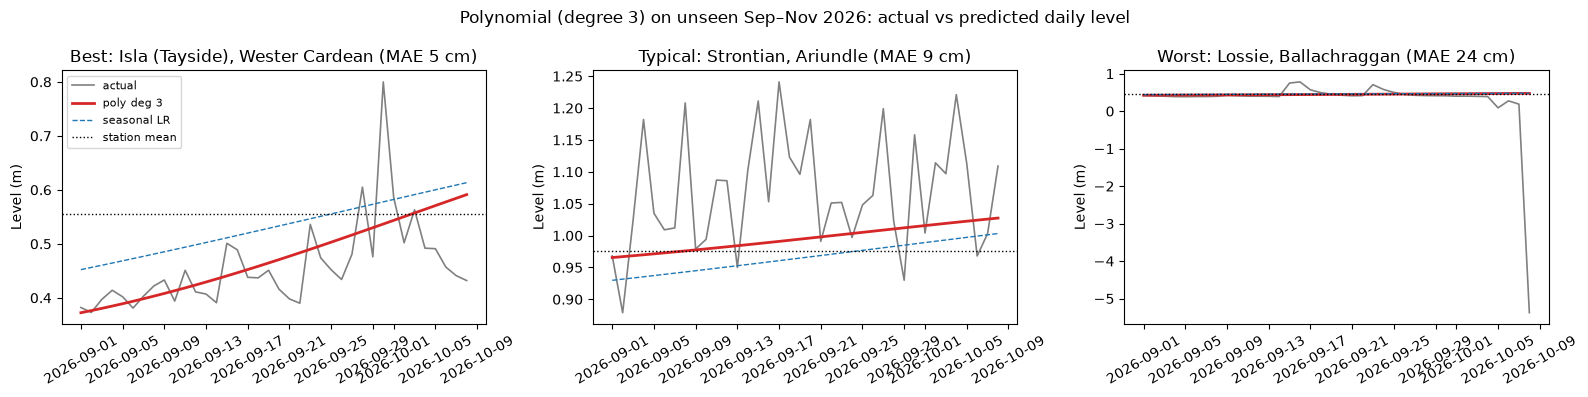

In [51]:
# 6.3 Actual vs predicted on Sep–Nov 2026 (final model: poly deg 3)
test_rows = test_df.copy()                     # same rows as X_test

test_rows["pred_z"]  = pred_z                  # poly deg 3 predictions from 6.1
test_rows["pred_m"]  = test_rows["pred_z"] * test_rows["sta_std"] + test_rows["sta_mean"]   # back to metres
test_rows["seas_m"]  = seasonal.predict(X_test[season_cols]) * test_rows["sta_std"] + test_rows["sta_mean"]   # optional: baseline in metres
test_rows["err_z"]   = (test_rows["z"] - test_rows["pred_z"]).abs()      # for ranking (fair across river sizes)
test_rows["abs_err"] = (test_rows["avg"] - test_rows["pred_m"]).abs()    # in metres, for the reader

# best / typical / worst station by average z-error
sta_err = test_rows.groupby("Observation_ID", observed = True)["err_z"].mean().sort_values()
picks = {"Best": sta_err.index[0], "Typical": sta_err.index[len(sta_err) // 2], "Worst": sta_err.index[-1]}

fig, axes = plt.subplots(1, 3, figsize = (16, 4))

for ax, (label, sta_id) in zip(axes, picks.items()):
    sta = test_rows[test_rows["Observation_ID"] == sta_id].sort_values("date")
    mae_cm = sta["abs_err"].mean() * 100
    ax.plot(sta["date"], sta["avg"],    color = "grey",    lw = 1.2, label = "actual")
    ax.plot(sta["date"], sta["pred_m"], color = "tab:red", lw = 2,   label = "poly deg 3")
    ax.plot(sta["date"], sta["seas_m"], color = "tab:blue", lw = 1, ls = "--", label = "seasonal LR")   # optional
    ax.axhline(sta["sta_mean"].iloc[0], color = "k", ls = ":", lw = 1, label = "station mean")
    ax.set_title(f"{label}: {sta['Station_Name'].iloc[0]} (MAE {mae_cm:.0f} cm)")
    ax.set_ylabel("Level (m)")
    ax.tick_params(axis = "x", rotation = 30)

axes[0].legend(fontsize = 8)
fig.suptitle("Polynomial (degree 3) on unseen Sep–Nov 2026: actual vs predicted daily level")
plt.tight_layout(); plt.show()

In [52]:
# 6.3b Error by month (all test stations): poly deg 3 vs seasonal LR
month = test_rows["date"].dt.month

mae_month = pd.DataFrame({
    "Poly deg 3 MAE (cm)":  test_rows["abs_err"].groupby(month).mean() * 100,
    "Seasonal LR MAE (cm)": (test_rows["avg"] - test_rows["seas_m"]).abs().groupby(month).mean() * 100,
}).round(1)

mae_month.index = mae_month.index.map({9: "Sep", 10: "Oct", 11: "Nov"})
mae_month

,Poly deg 3 MAE (cm),Seasonal LR MAE (cm)
date,,
Sep,12.1,13.7
Oct,12.2,12.7


MAE stays at about ____ cm in both September and October for the polynomial model, compared with ____ cm and ____ cm for seasonal LR.
The polynomial model's advantage is larger in ____ (____ cm) than in ____ (____ cm).
October contains only ____ days of data, so its figure is ____.
In practical terms, a typical daily forecast is off by about ____ cm, because the models capture the ____ pattern but not ____.

**Candidate models (chosen by time-ordered CV, RMSE in z units, folds 2022–2025)**

| Candidate (best setting) | CV mean ± sd | Case for choosing it | Case against choosing it |
|---|---|---|---|
| **Seasonal LR** (sin, cos) | 1.084 ± 0.180 | Simplest: 2 coefficients, one readable equation (peak ≈ late Dec); within 1 SE of the best (1-SE rule); beat both baselines in 3 of 4 autumns | Ignores location: one shared curve for all stations, so it cannot capture the larger autumn rise in the west |
| **Ridge** (α = 0.01) | 1.084 ± 0.180 | Uses all features with mild shrinkage | Best at the smallest α, so regularisation does nothing here (≈ 1M rows, no overfitting); same score as seasonal LR with ~20× more coefficients |
| **Lasso** (α = 0.01) | 1.083 ± 0.186 | Automatic feature selection; showed only sin/cos matter | Ends up as practically the seasonal model (only sin/cos survive), so it adds a tuning step for no gain |
| **Elastic net** (α = 0.1) | 1.083 ± 0.209 | Mix of lasso and ridge | Same score as lasso; highest year-to-year spread (sd 0.209) of all candidates |
| **Polynomial deg 3** (sin, cos, lat, lon) | 1.080 ± 0.167 | Joint-best CV; most consistent across years (lowest sd); beat seasonal LR in 3 of 4 autumns; trained on all rows, reproducible; captures the asymmetric autumn rise and the west/east difference | 34 terms that are hard to explain; gain over seasonal LR only 0.004 (< 1 SE); curve overshoots at the most western/eastern stations |
| **Kernel ridge** (α = 1, γ = 0.01) | 1.079 ± 0.190 | Lowest CV mean; flexible, no fixed formula | Tie with poly-3 (difference 0.001); trained on only 3,000 sampled rows, so the result depends on the sample; no equation to show; best γ at the edge of the grid; slow |

**Baselines (reference only)**

| Baseline | CV mean ± sd | Role |
|---|---|---|
| Past Sep–Nov mean (per station) | 1.127 ± 0.209 | Naive "this station's usual autumn" forecast |
| Predict 0 (station mean) | 1.134 ± 0.286 | "River stays at its normal level": the zero-effort bar |

<a id = "test"></a>
[<div style="text-align: right">TOP</div>](#top)

> ## **7. Test**

```
Limits (weather not in features, ~1.01 ceiling), future work (rainfall, Aug wetness, per-cluster curves)
```

<a id = "discussion"></a>
[<div style = "text-align: right">TOP</div>](#top)

> ## **8. Discussion**

<a id = "conclusion"></a>
[<div style = "text-align: right">TOP</div>](#top)

> ## **9. Conclusion**